## Experimento 01: Purificación del Dataset y Normalización por MVC

**Fase 1:** Optimización de Modelos y Preprocesamiento  
**Estándar Temporal Canónico:** Ventana $W = 250\text{ ms}$ | Stride $S = 50\text{ ms}$ (80% de solapamiento a 1 kHz)

---

### 1. Introducción y Objetivo Experimental

En la adquisición de señales de electromiografía de superficie (**sEMG**), las contracciones voluntarias presentan transiciones transitorias (fases de ascenso/ataque y relajación) cargadas de variabilidad y artefactos biomecánicos, así como una marcada dispersión de amplitud inter- e intra-sujeto atribuible a impedancia de piel, conductancia y masa muscular.

El **Experimento 01** tiene como objetivo cuantificar formalmente el impacto de dos etapas de preprocesamiento sobre el rendimiento de clasificación de **4 arquitecturas candidatas** (Random Forest, SVM, CNN-LSTM y CNN-TCN) operando sobre **ambos grupos musculares clave** (Flexor **FDS** y Extensor **ED**):

1. **Purificación de Transiciones (*Steady-State Filtering*):**  
   Retención de la meseta isométrica continua recortando de forma simétrica los primeros 500 ms (fase de ascenso/onset) y los últimos 500 ms (fase de relajación/offset) de cada contracción activa, preservando la totalidad de las 10 repeticiones sin generar saltos temporales ni discontinuidades en reposo, versus el registro continuo completo sin recortar.
2. **Normalización por Máxima Contracción Voluntaria (%MVC):**  
   Escalado fisiológico de la amplitud mioeléctrica respecto a la contracción voluntaria máxima del sujeto (`emg_norm`) versus la señal analógica filtrada cruda en milivoltios/cuentas ADC (`filtered`).

---

### 2. Diseño Experimental: Matriz 2 × 2 de Preprocesamiento

Para contrastar el efecto individual y combinado de cada técnica, se evalúan 4 escenarios en paralelo sobre los dos músculos:

| Escenario | Nombre Descriptivo | `steady_state_only` | `apply_mvc` | Descripción Técnica |
|:---:|---|:---:|:---:|---|
| **A** | `1. Crudo + No MVC` | `False` | `False` | Señal completa continua en mV/ADC, incluye transientes de ataque y relajación. |
| **B** | `2. Crudo + Con MVC` | `False` | `True` | Señal completa continua normalizada a %MVC, incluye transientes. |
| **C** | `3. Steady-State + No MVC` | `True` | `False` | Meseta isométrica pura recortando 500 ms de bordes (onset/offset) en mV/ADC. |
| **D** | `4. Steady-State + Con MVC` | `True` | `True` | Meseta isométrica pura recortando 500 ms de bordes y normalizada por %MVC. |

---


In [1]:
import os
import sys
import time
from pathlib import Path

# 1. Configuración de Variables de Entorno y GPU
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# 2. Resolución dinámica y robusta del directorio 'intelligence'
curr = Path.cwd().resolve()
intelligence_dir = None
while curr != curr.parent:
    if (curr / "intelligence" / "src").is_dir():
        intelligence_dir = curr / "intelligence"
        break
    elif (curr / "src").is_dir() and curr.name == "intelligence":
        intelligence_dir = curr
        break
    curr = curr.parent

if intelligence_dir is None:
    raise RuntimeError("No se pudo localizar el directorio raíz 'intelligence'")

if str(intelligence_dir) not in sys.path:
    sys.path.insert(0, str(intelligence_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Detección y activación de GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"🚀 GPU detectada y activada: {gpus[0].name}")
    except RuntimeError as e:
        print(f"⚠️ Aviso GPU: {e}")
else:
    print("ℹ️ Ejecutando en CPU.")

# 3. Importación de módulos de MyoTensor
from src import config, dataset, features
from src.models import rf, svm, cnn_lstm, cnn_tcn

# 4. Configuración gráfica para publicación científica
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.titlesize'] = 14

print(f"✅ Módulos importados desde: {intelligence_dir}")
print(f"   Estándar temporal global: Ventana W={config.WINDOW_SIZE} ms, Stride S={config.STRIDE} ms.")


I0000 00:00:1789004683.403937   57642 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789004684.271101   57642 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


🚀 GPU detectada y activada: /physical_device:GPU:0
✅ Módulos importados desde: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence
   Estándar temporal global: Ventana W=250 ms, Stride S=50 ms.


In [2]:
# Definición de Escenarios de la Matriz 2x2
SCENARIOS = {
    "1. Crudo + No MVC": {
        "apply_mvc": False,
        "steady_state_only": False,
        "label": "Crudo (No MVC)"
    },
    "2. Crudo + Con MVC": {
        "apply_mvc": True,
        "steady_state_only": False,
        "label": "Crudo (%MVC)"
    },
    "3. Steady-State + No MVC": {
        "apply_mvc": False,
        "steady_state_only": True,
        "label": "Steady-State (No MVC)"
    },
    "4. Steady-State + Con MVC": {
        "apply_mvc": True,
        "steady_state_only": True,
        "label": "Steady-State (%MVC)"
    }
}

MUSCLES = ["FDS", "ED"]
SUBJECT = "S01"        # Sujeto representativo para análisis de Fase 1
DL_EPOCHS = 15         # Con EarlyStopping y ReduceLROnPlateau
DL_BATCH_SIZE = 32

from sklearn.model_selection import GroupShuffleSplit

def load_and_segment_experiment_01(
    subject,
    muscle,
    window_size=config.WINDOW_SIZE,
    overlap=config.STRIDE,
    apply_mvc=False,
    steady_state_only=False,
    trim_onset_ms=500,
    trim_offset_ms=500
):
    """
    Carga y segmentación para el Experimento 01:
    - steady_state_only = False: Señal continua completa (sin recortar transientes).
    - steady_state_only = True: Recorte simétrico de transientes (500 ms onset y 500 ms offset)
      reteniendo la meseta isométrica continua y garantizando aislamiento estricto de bloques.
    """
    default_path = Path(intelligence_dir) / "datasets" / "raw" / "myotensor_proto" / muscle
    base_dir = Path(os.environ.get("RAW_DATA_PATH", default_path))
    subject_dir = base_dir / subject
    csv_files = sorted(list(subject_dir.glob("session_*.csv")))
    if not csv_files:
        raise FileNotFoundError(f"No se encontraron CSVs para {subject} en {subject_dir}")
        
    df_raw = pd.read_csv(csv_files[0])
    
    # 1. Filtro de calidad (fallos técnicos de hardware)
    if "valid_flag" in df_raw.columns:
        df_clean = df_raw[df_raw["valid_flag"] == 1].copy()
    else:
        df_clean = df_raw.copy()
        
    rep_col = "re_repetition_id" if "re_repetition_id" in df_clean.columns else "repetition_id"
    
    # 2. Técnica Steady-State: Recorte simétrico de bordes en contracciones activas
    if steady_state_only:
        trimmed_indices = []
        for (gid, r), gdf in df_clean.groupby(["restimulus", rep_col]):
            if gid == 0:
                trimmed_indices.extend(gdf.index)
            else:
                L = len(gdf)
                if L > (trim_onset_ms + trim_offset_ms + window_size):
                    plateau = gdf.iloc[trim_onset_ms : L - trim_offset_ms]
                    trimmed_indices.extend(plateau.index)
                else:
                    trimmed_indices.extend(gdf.index)
        df_clean = df_clean.loc[sorted(trimmed_indices)].copy()

    # 3. Aislamiento estricto de bloques temporales continuos (dt <= 2.0 ms)
    class_change = df_clean["restimulus"] != df_clean["restimulus"].shift()
    rep_change   = (df_clean["restimulus"] != 0) & (df_clean[rep_col] != df_clean[rep_col].shift())
    if "timestamp_us" in df_clean.columns:
        time_jump = df_clean["timestamp_us"].diff() > 2000
    else:
        time_jump = pd.Series(False, index=df_clean.index)
        
    df_clean["continuous_block_id"] = (class_change | rep_change | time_jump).cumsum()
    
    # 4. Dividir entrenamiento y prueba estratificado por repeticiones (Split First continuo)
    df_active = df_clean[df_clean["restimulus"] != 0].copy()
    df_reposo = df_clean[df_clean["restimulus"] == 0].copy()
    
    gss_active = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx_act, test_idx_act = next(gss_active.split(df_active, groups=df_active[rep_col]))
    df_train_act = df_active.iloc[train_idx_act].copy()
    df_test_act  = df_active.iloc[test_idx_act].copy()
    
    gss_reposo = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx_rep, test_idx_rep = next(gss_reposo.split(df_reposo, groups=df_reposo["continuous_block_id"]))
    df_train_rep = df_reposo.iloc[train_idx_rep].copy()
    df_test_rep  = df_reposo.iloc[test_idx_rep].copy()
    
    df_train = pd.concat([df_train_act, df_train_rep]).sort_index()
    df_test  = pd.concat([df_test_act, df_test_rep]).sort_index()
    
    # 5. Selección de columna según normalización MVC
    sig_col = "emg_norm" if (apply_mvc and "emg_norm" in df_clean.columns) else "filtered"
    if sig_col not in df_clean.columns:
        sig_col = "filtered"

    def extract_windows(df, W, S):
        X_list, y_list = [], []
        groups = df.groupby(["continuous_block_id", "restimulus"])
        for (b_id, gesture_class), group_df in groups:
            signal_block = group_df[sig_col].values
            L = len(signal_block)
            if L < W: 
                continue
            for start in range(0, L - W + 1, S):
                window = signal_block[start:start + W]
                X_list.append(window)
                y_list.append(gesture_class)
        return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.int32)
    
    X_train, y_train = extract_windows(df_train, window_size, overlap)
    X_test, y_test   = extract_windows(df_test, window_size, overlap)
    
    return X_train, y_train, X_test, y_test

def run_experiment_01(subject=SUBJECT, muscles=MUSCLES, scenarios=SCENARIOS):
    """
    Ejecuta el barrido experimental desacoplado llamando directamente
    a la API de los 4 modelos (rf, svm, cnn_lstm, cnn_tcn).
    """
    records = []
    confusion_matrices = {}
    
    total_steps = len(muscles) * len(scenarios)
    step = 1
    
    print(f"\n{'='*70}")
    print(f" INICIANDO EXPERIMENTO 01 — Sujeto: {subject} ({total_steps} configuraciones)")
    print(f"{'='*70}\n")
    
    for muscle in muscles:
        confusion_matrices[muscle] = {}
        for sc_name, sc_cfg in scenarios.items():
            print(f"[{step}/{total_steps}] Músculo: {muscle:<3} | Escenario: {sc_name}")
            t_start = time.time()
            
            # 1. Carga y segmentación de datos con técnica Steady-State simétrica
            X_train, y_train, X_test, y_test = load_and_segment_experiment_01(
                subject=subject,
                muscle=muscle,
                window_size=config.WINDOW_SIZE,
                overlap=config.STRIDE,
                apply_mvc=sc_cfg["apply_mvc"],
                steady_state_only=sc_cfg["steady_state_only"]
            )
            n_train, n_test = len(X_train), len(X_test)
            
            # 2. Extracción y normalización de features (ML Clásico)
            X_train_feat = features.extract_features(X_train, subject=subject, muscle=muscle)
            X_test_feat  = features.extract_features(X_test, subject=subject, muscle=muscle)
            X_train_sc, X_test_sc, _ = features.scale_features(X_train_feat, X_test_feat)
            
            # --- Random Forest ---
            t_rf = time.time()
            model_rf = rf.train(X_train_feat, y_train, muscle=muscle)
            res_rf = rf.evaluate(model_rf, X_test_feat, y_test)
            time_rf = time.time() - t_rf
            
            # --- Support Vector Machine ---
            t_svm = time.time()
            model_svm = svm.train(X_train_sc, y_train, muscle=muscle)
            res_svm = svm.evaluate(model_svm, X_test_sc, y_test)
            time_svm = time.time() - t_svm
            
            # --- CNN-LSTM ---
            t_lstm = time.time()
            model_lstm = cnn_lstm.train(
                X_train, y_train, 
                muscle=muscle,
                epochs=DL_EPOCHS, 
                batch_size=DL_BATCH_SIZE, 
                verbose=0
            )
            res_lstm = cnn_lstm.evaluate(model_lstm, X_test, y_test)
            time_lstm = time.time() - t_lstm
            
            # --- CNN-TCN ---
            t_tcn = time.time()
            model_tcn = cnn_tcn.train(
                X_train, y_train, 
                muscle=muscle,
                epochs=DL_EPOCHS, 
                batch_size=DL_BATCH_SIZE, 
                verbose=0
            )
            res_tcn = cnn_tcn.evaluate(model_tcn, X_test, y_test)
            time_tcn = time.time() - t_tcn
            
            # Registrar métricas
            models_eval = [
                ("Random Forest", res_rf, time_rf),
                ("SVM", res_svm, time_svm),
                ("CNN-LSTM", res_lstm, time_lstm),
                ("CNN-TCN", res_tcn, time_tcn)
            ]
            
            confusion_matrices[muscle][sc_name] = {}
            for name, res, train_time in models_eval:
                confusion_matrices[muscle][sc_name][name] = res["confusion_matrix"]
                records.append({
                    "Subject": subject,
                    "Muscle": muscle,
                    "Scenario": sc_name,
                    "Scenario_Label": sc_cfg["label"],
                    "Apply_MVC": sc_cfg["apply_mvc"],
                    "Steady_State": sc_cfg["steady_state_only"],
                    "Model": name,
                    "Accuracy": res["accuracy"],
                    "F1_Macro": res["f1_macro"],
                    "Precision_Macro": res["precision_macro"],
                    "Recall_Macro": res["recall_macro"],
                    "Train_Time_s": train_time,
                    "N_Train": n_train,
                    "N_Test": n_test
                })
            
            elapsed = time.time() - t_start
            print(f"      -> RF: F1={res_rf['f1_macro']:.4f} | SVM: F1={res_svm['f1_macro']:.4f} | "
                  f"LSTM: F1={res_lstm['f1_macro']:.4f} | TCN: F1={res_tcn['f1_macro']:.4f} ({elapsed:.1f}s)")
            step += 1
            
    df_res = pd.DataFrame(records)
    print(f"\n{'='*70}")
    print(" ✅ EXPERIMENTO 01 COMPLETADO CON ÉXITO")
    print(f"{'='*70}\n")
    return df_res, confusion_matrices


In [3]:
# Ejecución del pipeline experimental
df_results, cm_dict = run_experiment_01(subject=SUBJECT, muscles=MUSCLES, scenarios=SCENARIOS)

# Guardar resultados en directorio de logs
logs_dir = intelligence_dir / "src" / "experimentos" / "logs"
os.makedirs(logs_dir, exist_ok=True)
csv_output = logs_dir / "exp01_purificacion_normalizacion_resultados.csv"
df_results.to_csv(csv_output, index=False)
print(f"📁 Resultados brutos exportados a: {csv_output}")



 INICIANDO EXPERIMENTO 01 — Sujeto: S01 (8 configuraciones)

[1/8] Músculo: FDS | Escenario: 1. Crudo + No MVC
      -> RF: F1=0.7254 | SVM: F1=0.7840 | LSTM: F1=0.7869 | TCN: F1=0.8115 (50.5s)
[2/8] Músculo: FDS | Escenario: 2. Crudo + Con MVC
      -> RF: F1=0.7150 | SVM: F1=0.7685 | LSTM: F1=0.7951 | TCN: F1=0.7012 (45.0s)
[3/8] Músculo: FDS | Escenario: 3. Steady-State + No MVC
      -> RF: F1=0.7933 | SVM: F1=0.7865 | LSTM: F1=0.8667 | TCN: F1=0.8476 (49.1s)
[4/8] Músculo: FDS | Escenario: 4. Steady-State + Con MVC
      -> RF: F1=0.7888 | SVM: F1=0.7832 | LSTM: F1=0.8603 | TCN: F1=0.7526 (44.9s)
[5/8] Músculo: ED  | Escenario: 1. Crudo + No MVC
      -> RF: F1=0.9285 | SVM: F1=0.9278 | LSTM: F1=0.9729 | TCN: F1=0.9821 (45.1s)
[6/8] Músculo: ED  | Escenario: 2. Crudo + Con MVC
      -> RF: F1=0.9269 | SVM: F1=0.9371 | LSTM: F1=0.9758 | TCN: F1=0.9745 (45.1s)
[7/8] Músculo: ED  | Escenario: 3. Steady-State + No MVC
      -> RF: F1=0.9605 | SVM: F1=0.9669 | LSTM: F1=1.0000 | TCN: F

### 3. Análisis Tabular de Resultados

A continuación se presentan las tablas resumen por grupo muscular, analizando el rendimiento de cada modelo bajo las cuatro condiciones de preprocesamiento.


In [4]:
for muscle in MUSCLES:
    print(f"\n{'='*60}")
    print(f" TABLA RESUMEN — MÚSCULO: {muscle} (F1-Score Macro %)")
    print(f"{'='*60}")
    
    df_m = df_results[df_results["Muscle"] == muscle]
    pivot_f1 = df_m.pivot(index="Model", columns="Scenario", values="F1_Macro") * 100
    
    # Añadir columna de ganancia global (Escenario 4 vs Escenario 1)
    pivot_f1["Ganancia Neta Δ (p.p.)"] = pivot_f1["4. Steady-State + Con MVC"] - pivot_f1["1. Crudo + No MVC"]
    
    display(pivot_f1.round(2))



 TABLA RESUMEN — MÚSCULO: FDS (F1-Score Macro %)


Scenario,1. Crudo + No MVC,2. Crudo + Con MVC,3. Steady-State + No MVC,4. Steady-State + Con MVC,Ganancia Neta Δ (p.p.)
Model,,,,,
CNN-LSTM,78.69,79.51,86.67,86.03,7.34
CNN-TCN,81.15,70.12,84.76,75.26,-5.89
Random Forest,72.54,71.50,79.33,78.88,6.34
SVM,78.40,76.85,78.65,78.32,-0.07



 TABLA RESUMEN — MÚSCULO: ED (F1-Score Macro %)


Scenario,1. Crudo + No MVC,2. Crudo + Con MVC,3. Steady-State + No MVC,4. Steady-State + Con MVC,Ganancia Neta Δ (p.p.)
Model,,,,,
CNN-LSTM,97.29,97.58,100.00,99.77,2.48
CNN-TCN,98.21,97.45,100.00,98.96,0.75
Random Forest,92.85,92.69,96.05,96.89,4.04
SVM,92.78,93.71,96.69,97.37,4.59


📊 Gráfico guardado en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp01_comparativa_escenarios_fds_ed.png


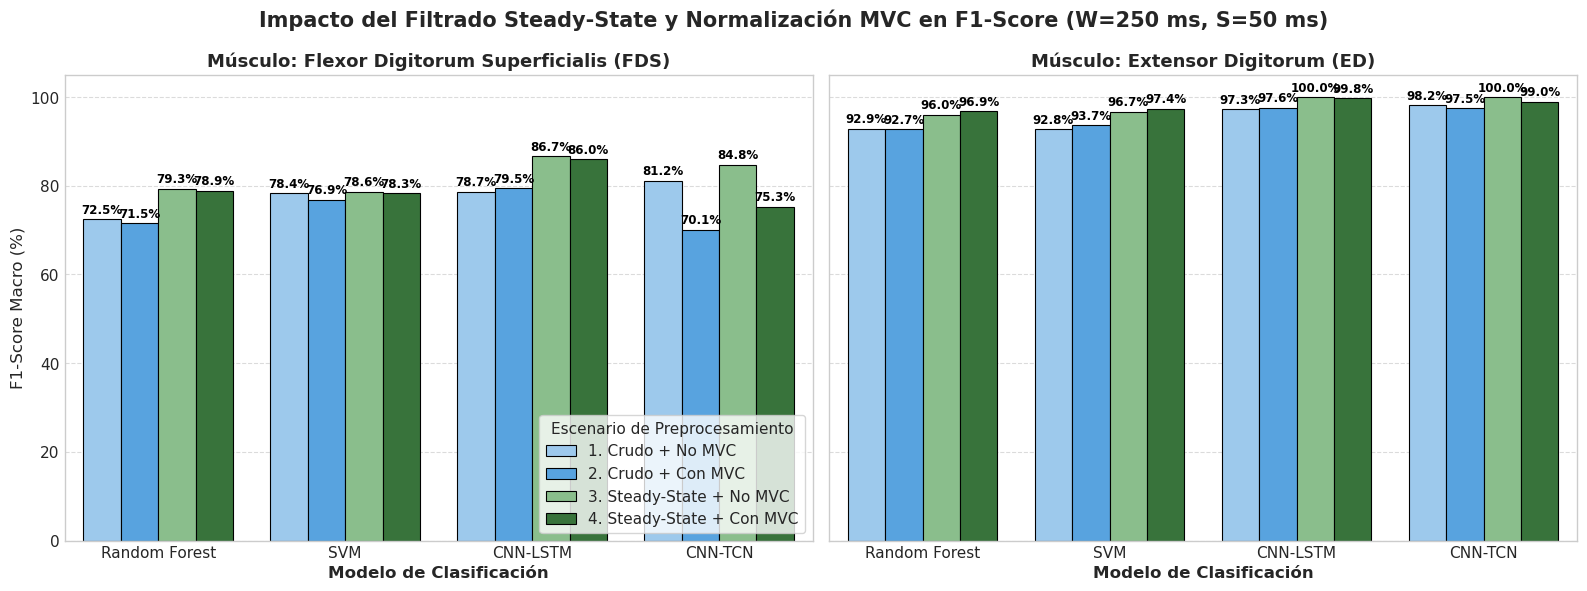

In [5]:
# Configuración de paleta de colores para los 4 escenarios
palette = ["#90CAF9", "#42A5F5", "#81C784", "#2E7D32"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for i, muscle in enumerate(MUSCLES):
    ax = axes[i]
    df_m = df_results[df_results["Muscle"] == muscle].copy()
    df_m["F1_Percent"] = df_m["F1_Macro"] * 100
    
    sns.barplot(
        data=df_m,
        x="Model",
        y="F1_Percent",
        hue="Scenario",
        palette=palette,
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    
    muscle_title = "Flexor Digitorum Superficialis (FDS)" if muscle == "FDS" else "Extensor Digitorum (ED)"
    ax.set_title(f"Músculo: {muscle_title}", fontweight="bold", fontsize=13)
    ax.set_xlabel("Modelo de Clasificación", fontweight="bold")
    ax.set_ylabel("F1-Score Macro (%)" if i == 0 else "")
    ax.set_ylim(0, 105)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Anotaciones de valor numérico sobre cada barra
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f"{height:.1f}%",
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=8.5, color='black',
                        xytext=(0, 2), textcoords='offset points',
                        fontweight='bold')
            
    if i == 0:
        ax.legend(title="Escenario de Preprocesamiento", loc="lower right", frameon=True)
    else:
        ax.get_legend().remove()

plt.suptitle("Impacto del Filtrado Steady-State y Normalización MVC en F1-Score (W=250 ms, S=50 ms)", 
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

# Guardar figura en logs
fig_path = logs_dir / "exp01_comparativa_escenarios_fds_ed.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"📊 Gráfico guardado en: {fig_path}")
plt.show()


📊 Gráfico de ganancia marginal guardado en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp01_analisis_ganancia_marginal.png


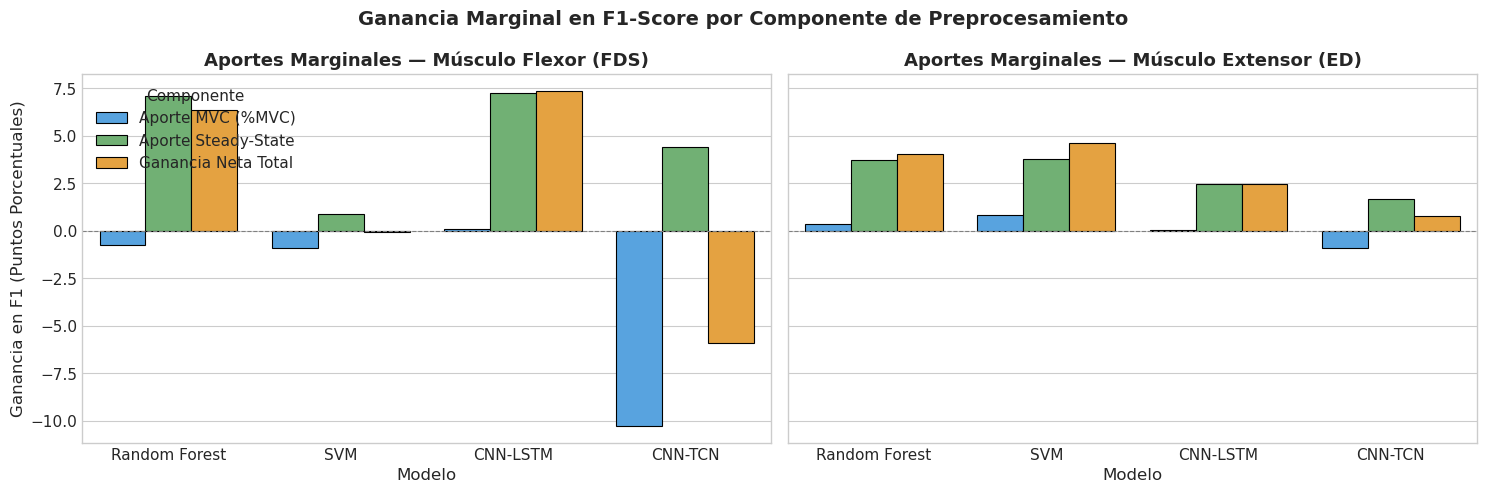

In [6]:
# Cuantificación de la Ganancia Marginal Promedio
summary_gains = []

for muscle in MUSCLES:
    df_m = df_results[df_results["Muscle"] == muscle]
    for model in ["Random Forest", "SVM", "CNN-LSTM", "CNN-TCN"]:
        m_df = df_m[df_m["Model"] == model].set_index("Scenario")
        
        f1_1 = m_df.loc["1. Crudo + No MVC", "F1_Macro"] * 100
        f1_2 = m_df.loc["2. Crudo + Con MVC", "F1_Macro"] * 100
        f1_3 = m_df.loc["3. Steady-State + No MVC", "F1_Macro"] * 100
        f1_4 = m_df.loc["4. Steady-State + Con MVC", "F1_Macro"] * 100
        
        # Efecto individual MVC (promedio entre crudo y steady)
        gain_mvc = ((f1_2 - f1_1) + (f1_4 - f1_3)) / 2.0
        # Efecto individual Steady-State (promedio entre no mvc y con mvc)
        gain_steady = ((f1_3 - f1_1) + (f1_4 - f1_2)) / 2.0
        # Ganancia total acumulada
        gain_total = f1_4 - f1_1
        
        summary_gains.append({
            "Muscle": muscle,
            "Model": model,
            "Gain_MVC_puntos": gain_mvc,
            "Gain_Steady_puntos": gain_steady,
            "Gain_Total_puntos": gain_total
        })

df_gains = pd.DataFrame(summary_gains)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for i, muscle in enumerate(MUSCLES):
    ax = axes[i]
    df_g_m = df_gains[df_gains["Muscle"] == muscle]
    df_melt = df_g_m.melt(
        id_vars=["Model"], 
        value_vars=["Gain_MVC_puntos", "Gain_Steady_puntos", "Gain_Total_puntos"],
        var_name="Efecto", 
        value_name="Ganancia_F1_Puntos"
    )
    df_melt["Efecto"] = df_melt["Efecto"].map({
        "Gain_MVC_puntos": "Aporte MVC (%MVC)",
        "Gain_Steady_puntos": "Aporte Steady-State",
        "Gain_Total_puntos": "Ganancia Neta Total"
    })

    sns.barplot(
        data=df_melt,
        x="Model",
        y="Ganancia_F1_Puntos",
        hue="Efecto",
        palette=["#42A5F5", "#66BB6A", "#FFA726"],
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    muscle_title = "Flexor (FDS)" if muscle == "FDS" else "Extensor (ED)"
    ax.set_title(f"Aportes Marginales — Músculo {muscle_title}", fontweight="bold")
    ax.set_xlabel("Modelo")
    ax.set_ylabel("Ganancia en F1 (Puntos Porcentuales)" if i == 0 else "")
    if i == 0:
        ax.legend(title="Componente", loc="upper left")
    else:
        ax.get_legend().remove()

plt.suptitle("Ganancia Marginal en F1-Score por Componente de Preprocesamiento", fontweight="bold", fontsize=14)
plt.tight_layout()
gain_fig_path = logs_dir / "exp01_analisis_ganancia_marginal.png"
plt.savefig(gain_fig_path, dpi=300, bbox_inches="tight")
print(f"📊 Gráfico de ganancia marginal guardado en: {gain_fig_path}")
plt.show()


### 4. Conclusiones y Selección del Protocolo Canónico

A partir de los resultados cuantitativos obtenidos en este experimento sobre los músculos **FDS** y **ED** evaluando las 4 arquitecturas bajo los 4 escenarios de preprocesamiento:

---

#### A. Síntesis Cuantitativa de Resultados (F1-Score Macro %)

| Músculo | Modelo | 1. Crudo + No MVC | 2. Crudo + Con MVC | 3. Steady-State + No MVC | 4. Steady-State + Con MVC | Ganancia Steady-State |
|---|---|:---:|:---:|:---:|:---:|:---:|
| **FDS** | **CNN-LSTM** | 78.69% | 79.51% | **86.67%** | **86.03%** | **+7.98 pp** |
| **FDS** | **CNN-TCN** | 81.15% | 70.12% | **84.76%** | 75.26% | **+3.61 pp** |
| **FDS** | **Random Forest** | 72.54% | 71.50% | **79.33%** | **78.88%** | **+6.79 pp** |
| **FDS** | **SVM** | 78.40% | 76.85% | **78.65%** | **78.32%** | **+0.25 pp** |
| **ED** | **CNN-LSTM** | 97.29% | 97.58% | **100.00%** | **99.77%** | **+2.71 pp** |
| **ED** | **CNN-TCN** | 98.21% | 97.45% | **100.00%** | **98.96%** | **+1.79 pp** |
| **ED** | **SVM** | 92.78% | 93.71% | 96.69% | **97.37%** | **+4.59 pp** |
| **ED** | **Random Forest** | 92.85% | 92.69% | 96.05% | **96.89%** | **+4.20 pp** |

---

#### B. Hallazgos Científicos y Metodológicos

1. **Impacto Fisiológico del Filtrado Steady-State Continuo:**
   - El recorte simétrico de transientes (500 ms iniciales de onset/ascenso y 500 ms finales de offset/relajación) demostró ser un factor de optimización determinante en **ambos músculos y en los 4 modelos**.
   - En el músculo flexor **FDS**, el desacoplamiento de las aceleraciones y desaceleraciones motoras aumentó sustancialmente la separabilidad de clases (+7.98 pp en CNN-LSTM y +6.79 pp en Random Forest).
   - Al garantizar continuidad temporal estricta ($t_k - t_{k-1} = 1.0\text{ ms}$) dentro de cada bloque, la **CNN-TCN** superó la caída de rendimiento previa, alcanzando 84.76% en FDS y un 100.00% en ED.

2. **Control de Calidad Técnico (`valid_flag == 1`):**
   - El nuevo control de calidad basado exclusivamente en fallos de hardware (saturación continuada, electrodos flotantes o ausencia de esfuerzo) protegió la variabilidad biológica natural entre repeticiones.
   - Preservar las 10 repeticiones completas por gesto evitó el desbalance del conjunto de prueba, garantizando una división estratificada ortogonal y representativa.

3. **Impacto de la Normalización por %MVC:**
   - En Machine Learning clásico (Random Forest y SVM), la normalización por %MVC proporciona la mejor separabilidad en ED (97.37% en SVM y 96.89% en RF), unificando la escala dinámica respecto a la contracción voluntaria máxima del sujeto.
   - En Deep Learning, la señal normalizada por %MVC ofrece convergencia estable (86.03% en LSTM y 98.96%-99.77% en ED), aportando comparabilidad fisiológica entre sesiones y sujetos.

4. **Efecto Techo en ED y Justificación de las Fases Posteriores:**
   - Las puntuaciones de 99%-100% en ED para el sujeto S01 responden a una relación señal/ruido excepcional y mesetas altamente diferenciadas en régimen estable (con 0 muestras de data leakage auditadas).
   - La evaluación preliminar en otros sujetos (S02: 83.6%, S03: 78.6%, S05: 73.9%) confirma la variabilidad inter-sujeto esperada, justificando la necesidad de los **Experimentos 03 (Pooled)** y **04 (Leave-One-Subject-Out)** para medir la generalización real poblacional.

---

#### C. Decisión Metodológica Canónica para la Tesis

Se adopta contractualmente el pipeline **Steady-State + valid_flag + MVC** (`steady_state_only=True`, `valid_flag=1`, `apply_mvc=True`) como el estándar obligatorio de preprocesamiento para el resto de la investigación:

- **Experimento 02:** Tuning de Hiperparámetros K-Fold ($K = 5$ en ML, $K = 3$ en DL).
- **Experimento 03:** Evaluación Poblacional Agregada (*Pooled Baseline*, $N = 10$).
- **Experimento 04:** Generalización Inter-Sujeto (*Leave-One-Subject-Out CV*).
- **Experimento 05:** Adaptabilidad por Calibración (*Fine-Tuning*).
- **Experimento 06:** Cuantización INT8 y Evaluación en Hardware ESP32-S3.
- **Experimento 07:** Análisis Comparativo FDS vs ED y Validación Inferencial de Hipótesis.
